# Лабораторная работа 2. Диагностика установления равновесия

**Цель:** определить, есть ли в рассчитанной периодической траектории стационарный участок, и оценить среднее двумерное давление с неопределённостью.

**Система:** та же модель 1035 атомов K, NVE, $24\times24$ нм, PBC по обеим осям.

**Ожидаемый результат:** графики температуры и давления с явной отметкой найденного переходного участка либо честный вывод, что заданный критерий не сработал.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> DEMO предназначен для демонстрации критерия и может не содержать достаточно длинного стационарного участка. FULL повторяет траекторию задания (30 000 шагов, 1 фс, seed 7). Отсутствие срабатывания не следует заменять выбранной вручную точкой.

## 1. Постановка задачи и физический смысл равновесия

Термодинамическое равновесие означает отсутствие макроскопически наблюдаемого направленного изменения состояния при фиксированных условиях; при этом микроскопическое движение и мгновенные значения давления и температуры продолжают флуктуировать. Сразу после запуска координаты расставлены по решётке, а не выбраны из равновесного распределения. Поэтому начальный участок может содержать релаксацию структуры и перераспределение между потенциальной и кинетической энергией.

В коде реализован конкретный эвристический критерий: сравниваются средние температуры и давления в двух соседних группах временных блоков; для давления изменение нормируется на идеальное 2D-давление. Критерий требует несколько последовательных успешных сравнений. Это диагностическое правило задания, а не строгий тест стационарности и не доказательство полного термодинамического равновесия. Если он не сработал, результат так и фиксируется.

Для выбранного участка рассчитываются среднее давление $\bar P$, выборочное стандартное отклонение $s=\sqrt{\sum(P_i-\bar P)^2/(n-1)}$ и стандартная ошибка среднего (SEM). При наличии как минимум двух целых блоков модуль оценивает SEM как $s_{block}/\sqrt{n_{block}}$, где $s_{block}$ — стандартное отклонение средних по блокам; это лучше учитывает кратковременную автокорреляцию, чем формула $s/\sqrt n$. Если данных мало для двух блоков, используется упрощённая оценка, которая может занижать ошибку при корреляции. Увеличение числа сохранённых кадров не эквивалентно такому же увеличению независимой статистики.

Давление здесь — двумерное вириальное $P_{2D}=(K+W/2)/A$ в Н/м. Математическая модель, параметры и ограничения K–K описаны в работах 00–01; в этой работе основной новый вопрос — статистическая стационарность, а не повторное объяснение потенциала.

### Исходные параметры расчёта

| Параметр | Значение FULL | Единица | Пояснение |
|---|---:|---|---|
| Число атомов | 1035 | 1 | Вариант K, 4 моль/л |
| Температура и начальное условие | 1173.15 | K | 900 °C + 273.15; в NVE не закрепляется термостатом |
| Коробка / площадь | 24 × 24 / 576 | нм / нм² | PBC по x и y |
| Масса K | 6.4924·10⁻²⁶ | кг | 39.0983 u |
| $\sigma$, $\varepsilon/k_B$ | 0.4250; 850 | нм; K | Зафиксированные параметры учебной модели |
| $\Delta t$, длительность | 1; 30 000 | фс; шагов | FULL = 30 пс, sample interval = 1 |
| Seed | 7 | — | Повторяемая начальная конфигурация |
| Блок критерия | 2000 наблюдений | — | 5 блоков сравнения, 3 последовательных сравнения; допуски T 2%, P 5% идеального масштаба |

В DEMO число частиц и физические параметры не меняются, сокращаются только траектория и размер блоков; значения DEMO напечатаны в конфигурационной ячейке.

## 2. Режим, seed и конфигурация

`default_config` создаёт неизменяемую конфигурацию с числом частиц, температурой, SI-массой, коробкой, шагом времени, cutoff и настройками периодичности. Значение `seed=7` фиксирует случайную инициализацию. `run_nve` возвращает временные ряды; здесь кадры координат не нужны, поэтому `frame_interval` выбран больше длины расчёта. В FULL используется блок в 2000 сохранённых наблюдений и настройка критерия из скрипта задания: пять блоков для каждого среднего и три последовательных сравнения. В DEMO параметры блоков явно сокращены, чтобы проиллюстрировать логику на коротком ряду; такой критерий DEMO не является выводом о физическом равновесии.

### Вычислительное ядро внутри notebook

Ниже приведён весь код, необходимый для расчёта. Блоки расположены в порядке зависимостей: от физических параметров к силам и интегратору. Каждый блок можно читать, изменять и выполнять как обычную Python-ячейку; скрытой загрузки кода нет.

In [ ]:
from pathlib import Path

# В Colab это /content; локально — каталог, из которого открыт notebook.
PROJECT_ROOT = Path.cwd()
print(f'Рабочий каталог: {PROJECT_ROOT}; результаты будут сохранены в output/')

#### Физические константы и параметры взаимодействия

Задаём единицы СИ, массу атома калия и параметры потенциалов K–K и K–C. Все энергии относятся к одной взаимодействующей паре, а не к молю.

In [ ]:
"""Physical constants and the fixed material parameters of the model.

The simulation core uses SI units. Energies are per particle, not per mole.
"""

from __future__ import annotations

from dataclasses import dataclass
import math


AVOGADRO = 6.022_140_76e23  # 1/mol, exact
BOLTZMANN = 1.380_649e-23  # J/K, exact
ATOMIC_MASS_UNIT = 1.660_539_066_60e-27  # kg

KELVIN_OFFSET_CELSIUS = 273.15
TEMPERATURE_C = 900.0
TEMPERATURE_K = TEMPERATURE_C + KELVIN_OFFSET_CELSIUS

MASS_K = 39.0983 * ATOMIC_MASS_UNIT
SIGMA_K = 0.4250e-9  # m
EPSILON_K = 850.0 * BOLTZMANN  # J/particle

# UFF C_3 values are used only for the fixed diamond wall. UFF lists the
# minimum position x and well depth D; sigma=x/2**(1/6) maps that minimum to
# the conventional 12-6 LJ form used by this project.
SIGMA_C = (3.851e-10) / (2.0 ** (1.0 / 6.0))
EPSILON_C = 0.105 * 4184.0 / AVOGADRO  # 0.105 kcal/mol -> J/particle
SIGMA_KC = 0.5 * (SIGMA_K + SIGMA_C)
EPSILON_KC = math.sqrt(EPSILON_K * EPSILON_C)
DIAMOND_LATTICE_CONSTANT = 0.3567e-9  # m
WALL_SPACING = DIAMOND_LATTICE_CONSTANT / math.sqrt(2.0)

LAYER_THICKNESS = (1.0e-3 / (4.0 * AVOGADRO)) ** (1.0 / 3.0)


@dataclass(frozen=True)
class LJParameters:
    sigma: float
    epsilon: float

    def __post_init__(self) -> None:
        if self.sigma <= 0.0 or self.epsilon <= 0.0:
            raise ValueError("LJ sigma and epsilon must be positive")

    @property
    def r_min(self) -> float:
        return 2.0 ** (1.0 / 6.0) * self.sigma

    @property
    def timescale(self) -> float:
        return self.sigma * math.sqrt(MASS_K / self.epsilon)


K_LJ = LJParameters(SIGMA_K, EPSILON_K)
C_LJ = LJParameters(SIGMA_C, EPSILON_C)
KC_LJ = LJParameters(SIGMA_KC, EPSILON_KC)


#### Геометрия и параметры расчёта

Собираем размер области, шаг интегрирования, число частиц, граничные условия и диагностические допуски в одну проверяемую конфигурацию.

In [ ]:
"""Configuration objects for the 2D MD engine."""

from __future__ import annotations

from dataclasses import dataclass, field
import math



@dataclass(frozen=True)
class Box:
    lx: float = 24.0e-9
    ly: float = 24.0e-9

    @property
    def area(self) -> float:
        return self.lx * self.ly


@dataclass(frozen=True)
class MDConfig:
    n_particles: int = 1035
    temperature: float = TEMPERATURE_K
    mass: float = MASS_K
    box: Box = field(default_factory=Box)
    lj: object = K_LJ
    cutoff_factor: float = 2.5
    dt: float = 1.0e-15
    periodic_x: bool = True
    periodic_y: bool = True
    remove_com: bool = True
    seed: int = 7
    force_backend: str = "bruteforce"
    wall_mode: str = "none"
    max_force_factor: float = 1.0e6
    max_relative_energy_drift: float = 5.0e-3

    @property
    def cutoff(self) -> float:
        return self.cutoff_factor * self.lj.sigma

    @property
    def degrees_of_freedom(self) -> int:
        removed = 2 if self.remove_com else 0
        return 2 * self.n_particles - removed

    def validate(self) -> None:
        if self.n_particles < 2:
            raise ValueError("At least two particles are required")
        if self.temperature <= 0.0 or self.mass <= 0.0 or self.dt <= 0.0:
            raise ValueError("temperature, mass, and dt must be positive")
        if self.cutoff_factor <= 0.0:
            raise ValueError("cutoff_factor must be positive")
        if self.periodic_x and self.cutoff >= self.box.lx / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic x box")
        if self.periodic_y and self.cutoff >= self.box.ly / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic y box")
        if self.degrees_of_freedom <= 0:
            raise ValueError("number of thermal degrees of freedom must be positive")
        if self.force_backend not in {"bruteforce", "cell_list"}:
            raise ValueError("force_backend must be 'bruteforce' or 'cell_list'")
        if self.wall_mode not in {"none", "all", "x"}:
            raise ValueError("wall_mode must be 'none', 'all', or 'x'")
        if self.wall_mode == "all" and (self.periodic_x or self.periodic_y):
            raise ValueError("all fixed walls require non-periodic x and y")
        if self.wall_mode == "x" and (self.periodic_x is True or self.periodic_y is False):
            raise ValueError("x-wall geometry requires x fixed and y periodic")
        if self.max_force_factor <= 0.0 or self.max_relative_energy_drift <= 0.0:
            raise ValueError("numerical safety thresholds must be positive")


def default_config(**overrides: object) -> MDConfig:
    values = {name: getattr(MDConfig(), name) for name in MDConfig.__dataclass_fields__}
    values.update(overrides)
    config = MDConfig(**values)
    config.validate()
    return config


#### Граничные условия

Реализуем периодическое заворачивание координат, minimum-image расстояние и отражение от непериодических границ.

In [ ]:
"""Boundary and minimum-image operations for rectangular 2D boxes."""

from __future__ import annotations

import numpy as np



def minimum_image(
    displacement: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    result = np.asarray(displacement, dtype=np.float64).copy()
    if periodic_x:
        result[..., 0] -= box.lx * np.round(result[..., 0] / box.lx)
    if periodic_y:
        result[..., 1] -= box.ly * np.round(result[..., 1] / box.ly)
    return result


def wrap_positions(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    wrapped = np.asarray(positions, dtype=np.float64).copy()
    if periodic_x:
        wrapped[:, 0] %= box.lx
    if periodic_y:
        wrapped[:, 1] %= box.ly
    return wrapped


def validate_positions_in_box(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> None:
    """Reject crossing of a fixed boundary instead of silently clipping it."""
    values = np.asarray(positions)
    if not np.all(np.isfinite(values)):
        raise FloatingPointError("non-finite coordinates after integration")
    tolerance = 1.0e-15
    if not periodic_x and (
        np.any(values[:, 0] < -tolerance) or np.any(values[:, 0] > box.lx + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed x boundary")
    if not periodic_y and (
        np.any(values[:, 1] < -tolerance) or np.any(values[:, 1] > box.ly + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed y boundary")


#### Парный потенциал Леннарда — Джонса

Вычисляем энергию и производную LJ, затем обрезаем и сдвигаем энергию на радиусе cutoff. Проверка отдельно останавливает численно опасные сближения.

In [ ]:
"""Analytic Lennard-Jones and truncated-shifted Lennard-Jones functions."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np



class NumericalInstabilityError(RuntimeError):
    """Raised when a pair distance is too small for a stable LJ evaluation."""


@dataclass(frozen=True)
class LJTS:
    parameters: LJParameters
    cutoff: float
    minimum_distance: float = 1.0e-15

    def __post_init__(self) -> None:
        if self.cutoff <= 0.0:
            raise ValueError("cutoff must be positive")
        if self.minimum_distance <= 0.0:
            raise ValueError("minimum_distance must be positive")

    def energy_and_radial_derivative(self, distance: float) -> tuple[float, float]:
        if not np.isfinite(distance) or distance < self.minimum_distance:
            raise NumericalInstabilityError(
                f"invalid pair distance r={distance:.6e} m"
            )
        if distance >= self.cutoff:
            return 0.0, 0.0

        u_lj, derivative = lj_energy_and_radial_derivative(distance, self.parameters)
        u_cut, _ = lj_energy_and_radial_derivative(self.cutoff, self.parameters)
        return u_lj - u_cut, derivative

    def force_on_i(self, displacement_i_from_j: np.ndarray) -> tuple[float, np.ndarray]:
        distance = float(np.linalg.norm(displacement_i_from_j))
        energy, derivative = self.energy_and_radial_derivative(distance)
        if derivative == 0.0:
            return energy, np.zeros(2, dtype=np.float64)
        # displacement is r_i-r_j; force is -grad_{r_i} U.
        force = -derivative * displacement_i_from_j / distance
        return energy, force


def lj_energy_and_radial_derivative(
    distance: float, parameters: LJParameters
) -> tuple[float, float]:
    """Return the unshifted LJ energy and dU/dr."""
    if not np.isfinite(distance) or distance <= 0.0:
        raise NumericalInstabilityError(f"invalid pair distance r={distance:.6e} m")
    sigma = parameters.sigma
    epsilon = parameters.epsilon
    sr6 = (sigma / distance) ** 6
    energy = 4.0 * epsilon * (sr6 * sr6 - sr6)
    derivative = 24.0 * epsilon / distance * (sr6 - 2.0 * sr6 * sr6)
    return energy, derivative


#### Начальные координаты и скорости

Частицы размещаются на слегка возмущённой решётке. Скорости выбираются из распределения Максвелла, затем удаляется движение центра масс и задаётся температура.

In [ ]:
"""Reproducible initial coordinates and Maxwell-Boltzmann velocities."""

from __future__ import annotations

import numpy as np



def _stream_rng(config: MDConfig, stream: int) -> np.random.Generator:
    """Create one deterministic, independent stream for a state component."""
    streams = np.random.SeedSequence(config.seed).spawn(2)
    return np.random.default_rng(streams[stream])


def lattice_positions(
    config: MDConfig,
    jitter_fraction: float = 0.08,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Place particles on a near-uniform 2D lattice with reproducible jitter."""
    if not 0.0 <= jitter_fraction < 0.25:
        raise ValueError("jitter_fraction must be in [0, 0.25)")

    margin = 0.0
    if config.wall_mode in {"all", "x"}:
        margin = 0.75 * KC_LJ.r_min
    if config.wall_mode == "all":
        lower = np.array([margin, margin])
        upper = np.array([config.box.lx - margin, config.box.ly - margin])
    elif config.wall_mode == "x":
        lower = np.array([margin, 0.0])
        upper = np.array([config.box.lx - margin, config.box.ly])
    else:
        lower = np.zeros(2)
        upper = np.array([config.box.lx, config.box.ly])
    available = upper - lower
    n_x = int(np.ceil(np.sqrt(config.n_particles * available[0] / available[1])))
    n_y = int(np.ceil(config.n_particles / n_x))
    spacing_x = available[0] / n_x
    spacing_y = available[1] / n_y
    capacity = n_x * n_y
    # Evenly sample the flattened lattice instead of taking a contiguous
    # prefix, which would leave a visibly underfilled final row.
    selected = np.floor(
        (np.arange(config.n_particles, dtype=np.float64) + 0.5)
        * capacity
        / config.n_particles
    ).astype(np.intp)
    ix = selected % n_x
    iy = selected // n_x
    positions = np.column_stack(
        (lower[0] + (ix + 0.5) * spacing_x, lower[1] + (iy + 0.5) * spacing_y)
    ).astype(np.float64)

    if jitter_fraction:
        rng = _stream_rng(config, 0) if rng is None else rng
        jitter = rng.uniform(-jitter_fraction, jitter_fraction, positions.shape)
        positions[:, 0] += jitter[:, 0] * spacing_x
        positions[:, 1] += jitter[:, 1] * spacing_y
    return positions


def maxwell_boltzmann_velocities(
    config: MDConfig,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Generate 2D velocities, remove COM motion, and rescale to target T."""
    rng = _stream_rng(config, 1) if rng is None else rng
    scale = np.sqrt(BOLTZMANN * config.temperature / config.mass)
    velocities = rng.normal(0.0, scale, size=(config.n_particles, 2))
    if config.remove_com:
        velocities -= velocities.mean(axis=0)

    kinetic = 0.5 * config.mass * np.sum(velocities * velocities)
    measured = 2.0 * kinetic / (config.degrees_of_freedom * BOLTZMANN)
    if not np.isfinite(measured) or measured <= 0.0:
        raise FloatingPointError("invalid initial kinetic temperature")
    velocities *= np.sqrt(config.temperature / measured)
    return velocities


def initialize(config: MDConfig) -> tuple[np.ndarray, np.ndarray]:
    config.validate()
    position_seed, velocity_seed = np.random.SeedSequence(config.seed).spawn(2)
    return lattice_positions(
        config, rng=np.random.default_rng(position_seed)
    ), maxwell_boltzmann_velocities(
        config, rng=np.random.default_rng(velocity_seed)
    )


#### Измеряемые физические величины

Определяем кинетическую энергию, мгновенную температуру, двумерное вириальное давление и механическое давление на x-стенки.

In [ ]:
"""Thermodynamic observables for a 2D system."""

from __future__ import annotations

import numpy as np



def kinetic_energy(velocities: np.ndarray, mass: float) -> float:
    return float(0.5 * mass * np.sum(np.asarray(velocities) ** 2))


def instantaneous_temperature(
    velocities: np.ndarray,
    mass: float,
    remove_com: bool = True,
) -> float:
    values = np.asarray(velocities, dtype=np.float64)
    if remove_com:
        values = values - values.mean(axis=0)
    dof = 2 * len(values) - (2 if remove_com else 0)
    return 2.0 * kinetic_energy(values, mass) / (dof * BOLTZMANN)


def pressure_2d(kinetic: float, virial: float, area: float) -> float:
    return (kinetic + 0.5 * virial) / area


def pressure_on_x_walls(
    wall_positions: np.ndarray,
    wall_reaction: np.ndarray,
    box_length_y: float,
) -> tuple[float, float, float]:
    """Return left, right, and mean mechanical pressure in N/m."""
    tolerance = max(1.0e-15, box_length_y * 1.0e-12)
    left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
    right = np.isclose(
        wall_positions[:, 0], np.max(wall_positions[:, 0]), atol=tolerance
    )
    left_pressure = abs(float(np.sum(wall_reaction[left, 0]))) / box_length_y
    right_pressure = abs(float(np.sum(wall_reaction[right, 0]))) / box_length_y
    return left_pressure, right_pressure, 0.5 * (left_pressure + right_pressure)


#### Геометрия углеродных стенок

Строим фиксированные ряды атомов углерода с шагом алмазной решётки. Эти атомы создают внешнее поле, но сами не интегрируются во времени.

In [ ]:
"""Fixed one-layer diamond-carbon wall geometry."""

from __future__ import annotations

import numpy as np



def _line_positions(length: float) -> np.ndarray:
    count = max(2, int(np.floor(length / WALL_SPACING)) + 1)
    return np.linspace(0.0, length, count, dtype=np.float64)


def _periodic_line_positions(length: float) -> np.ndarray:
    count = max(1, int(np.floor(length / WALL_SPACING)))
    return np.arange(count, dtype=np.float64) * (length / count)


def diamond_wall_positions(box: Box, mode: str) -> np.ndarray:
    """Return one fixed C-atom line per required side.

    In this strictly 2D representation, (100) diamond surface order is
    represented by the in-plane spacing a/sqrt(2). Corner atoms are unique.
    """
    if mode not in {"all", "x"}:
        raise ValueError("wall mode must be 'all' or 'x'")
    atoms: set[tuple[float, float]] = set()
    y_values = _periodic_line_positions(box.ly) if mode == "x" else _line_positions(box.ly)
    x_values = _line_positions(box.lx)
    for y in y_values:
        atoms.add((0.0, float(y)))
        atoms.add((box.lx, float(y)))
    if mode == "all":
        for x in x_values:
            atoms.add((float(x), 0.0))
            atoms.add((float(x), box.ly))
    return np.asarray(sorted(atoms), dtype=np.float64)


#### Расчёт межатомных сил

Суммируем парные силы, потенциальную энергию и вириал. Для больших систем используется список пространственных ячеек; поддерживается и взаимодействие со стенками.

In [ ]:
"""Reference O(N^2) pair-force calculation."""

from __future__ import annotations

import numpy as np



def compute_forces_bruteforce(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Return forces, potential energy, and positive-repulsion virial.

    ``displacement = r_i-r_j`` and the returned pair force is force on i
    from j. The stored virial is ``sum(displacement dot force_i)`` so that
    the 2D pressure is ``(kinetic_energy + virial / 2) / area``.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    forces = np.zeros_like(coordinates)
    potential_energy = 0.0
    virial = 0.0
    for i in range(len(coordinates) - 1):
        for j in range(i + 1, len(coordinates)):
            displacement = minimum_image(
                coordinates[i] - coordinates[j],
                box,
                periodic_x=periodic_x,
                periodic_y=periodic_y,
            )
            energy, force_i = potential.force_on_i(displacement)
            forces[i] += force_i
            forces[j] -= force_i
            potential_energy += energy
            virial += float(np.dot(displacement, force_i))

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces_cell_list(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Cell-list version of the pair calculation.

    The cell width is chosen not smaller than the cutoff, so the 3x3
    neighboring-cell stencil is sufficient. Pair arithmetic is intentionally
    identical to the reference backend.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    lengths = np.array([box.lx, box.ly], dtype=np.float64)
    periodic = (periodic_x, periodic_y)
    n_cells = np.maximum(1, np.floor(lengths / potential.cutoff).astype(int))
    cell_width = lengths / n_cells
    cell_of_particle = np.floor(coordinates / cell_width).astype(int)
    for axis in range(2):
        cell_of_particle[:, axis] = np.clip(
            cell_of_particle[:, axis], 0, n_cells[axis] - 1
        )

    cells: dict[tuple[int, int], list[int]] = {}
    for particle, cell in enumerate(cell_of_particle):
        key = (int(cell[0]), int(cell[1]))
        cells.setdefault(key, []).append(particle)

    pair_i: list[int] = []
    pair_j: list[int] = []
    for i, cell in enumerate(cell_of_particle):
        neighbor_keys: set[tuple[int, int]] = set()
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                candidate = [int(cell[0] + dx), int(cell[1] + dy)]
                valid = True
                for axis, is_periodic in enumerate(periodic):
                    if is_periodic:
                        candidate[axis] %= int(n_cells[axis])
                    elif not 0 <= candidate[axis] < n_cells[axis]:
                        valid = False
                if valid:
                    neighbor_keys.add((candidate[0], candidate[1]))

        for key in neighbor_keys:
            for j in cells.get(key, ()):
                if j <= i:
                    continue
                pair_i.append(i)
                pair_j.append(j)

    forces = np.zeros_like(coordinates)
    if pair_i:
        indices_i = np.asarray(pair_i, dtype=np.intp)
        indices_j = np.asarray(pair_j, dtype=np.intp)
        displacements = minimum_image(
            coordinates[indices_i] - coordinates[indices_j],
            box,
            periodic_x=periodic_x,
            periodic_y=periodic_y,
        )
        distances = np.linalg.norm(displacements, axis=1)
        active = distances < potential.cutoff
        if np.any(distances[active] < potential.minimum_distance):
            bad_distance = float(np.min(distances[active]))
            raise FloatingPointError(f"invalid pair distance r={bad_distance:.6e} m")
        if np.any(active):
            active_i = indices_i[active]
            active_j = indices_j[active]
            active_displacements = displacements[active]
            active_distances = distances[active]
            sigma = potential.parameters.sigma
            epsilon = potential.parameters.epsilon
            sr6 = (sigma / active_distances) ** 6
            sr6_cut = (sigma / potential.cutoff) ** 6
            u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
            pair_energy = 4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut
            derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
            pair_forces = -derivative[:, None] * active_displacements / active_distances[:, None]
            np.add.at(forces, active_i, pair_forces)
            np.add.at(forces, active_j, -pair_forces)
            potential_energy = float(np.sum(pair_energy))
            virial = float(np.sum(np.einsum("ij,ij->i", active_displacements, pair_forces)))
        else:
            potential_energy = 0.0
            virial = 0.0
    else:
        potential_energy = 0.0
        virial = 0.0

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
    backend: str = "bruteforce",
) -> tuple[np.ndarray, float, float]:
    if backend == "bruteforce":
        return compute_forces_bruteforce(
            positions, box, potential, periodic_x, periodic_y
        )
    if backend == "cell_list":
        return compute_forces_cell_list(
            positions, box, potential, periodic_x, periodic_y
        )
    raise ValueError(f"unknown force backend: {backend}")


def compute_forces_with_walls(
    positions: np.ndarray,
    box: Box,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
    periodic_x: bool,
    periodic_y: bool,
    backend: str = "cell_list",
) -> tuple[np.ndarray, float, float, np.ndarray]:
    """Gas-gas plus gas-fixed-wall interactions.

    ``wall_reaction`` is the force exerted by gas on each fixed wall atom.
    Wall-wall energy is omitted because fixed wall coordinates make it a
    constant irrelevant to gas dynamics.
    """
    gas_forces, gas_energy, gas_virial = compute_forces(
        positions,
        box,
        gas_potential,
        periodic_x,
        periodic_y,
        backend,
    )
    walls = np.asarray(wall_positions, dtype=np.float64)
    displacement = np.asarray(positions)[:, None, :] - walls[None, :, :]
    displacement = minimum_image(
        displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
    )
    distances = np.linalg.norm(displacement, axis=2)
    active = distances < wall_potential.cutoff
    if np.any(distances[active] < wall_potential.minimum_distance):
        raise FloatingPointError("K atom overlaps a fixed carbon wall atom")

    pair_forces = np.zeros_like(displacement)
    pair_energy = 0.0
    wall_virial = 0.0
    if np.any(active):
        active_distances = distances[active]
        sigma = wall_potential.parameters.sigma
        epsilon = wall_potential.parameters.epsilon
        sr6 = (sigma / active_distances) ** 6
        sr6_cut = (sigma / wall_potential.cutoff) ** 6
        u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
        pair_energy = float(np.sum(4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut))
        derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
        pair_forces[active] = -derivative[:, None] * displacement[active] / active_distances[:, None]
        wall_virial = float(np.sum(displacement[active] * pair_forces[active]))

    gas_forces += np.sum(pair_forces, axis=1)
    wall_reaction = -np.sum(pair_forces, axis=0)
    total_energy = gas_energy + pair_energy
    total_virial = gas_virial + wall_virial
    if not np.all(np.isfinite(gas_forces)) or not np.isfinite(total_energy):
        raise FloatingPointError("non-finite wall force or energy")
    return gas_forces, total_energy, total_virial, wall_reaction


#### Интегрирование уравнений движения

Один шаг velocity Verlet последовательно обновляет координаты, силы и скорости. Есть варианты для периодической системы и системы с фиксированными стенками.

In [ ]:
"""Time integration schemes."""

from __future__ import annotations

import numpy as np



def velocity_verlet_step(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float]:
    """Advance one NVE step and return new state plus U and virial."""
    acceleration = forces / config.mass
    new_positions = (
        positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    )
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial = compute_forces(
        new_positions,
        config.box,
        potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return new_positions, new_velocities, new_forces, potential_energy, virial


def velocity_verlet_step_with_walls(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float, np.ndarray]:
    """Velocity Verlet for mobile K atoms in a fixed external wall field."""
    acceleration = forces / config.mass
    new_positions = positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial, wall_reaction = compute_forces_with_walls(
        new_positions,
        config.box,
        gas_potential,
        wall_positions,
        wall_potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return (
        new_positions,
        new_velocities,
        new_forces,
        potential_energy,
        virial,
        wall_reaction,
    )


#### Движок молекулярной динамики

Объединяем инициализацию, силы, интегратор и наблюдаемые величины. `MDEngine` выполняет шаги, а `run_nve` сохраняет временные ряды и кадры траектории.

In [ ]:
"""Small reference MD engine used by the tests and later experiments."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np



@dataclass
class MDState:
    positions: np.ndarray
    velocities: np.ndarray
    forces: np.ndarray
    potential_energy: float
    virial: float
    wall_reaction: np.ndarray | None = None
    step: int = 0

    @property
    def kinetic_energy(self) -> float:
        raise AttributeError("kinetic energy requires the engine mass")


class MDEngine:
    def __init__(self, config: MDConfig, positions: np.ndarray | None = None, velocities: np.ndarray | None = None):
        config.validate()
        self.config = config
        self.potential = LJTS(config.lj, config.cutoff)
        self.wall_positions = (
            diamond_wall_positions(config.box, config.wall_mode)
            if config.wall_mode != "none"
            else None
        )
        self.wall_potential = (
            LJTS(KC_LJ, 2.5 * KC_LJ.sigma)
            if self.wall_positions is not None
            else None
        )
        if positions is None or velocities is None:
            positions, velocities = initialize(config)
        self.state = self._make_state(positions, velocities)

    def _make_state(self, positions: np.ndarray, velocities: np.ndarray) -> MDState:
        if self.wall_positions is None:
            forces, energy, virial = compute_forces(
                positions,
                self.config.box,
                self.potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
            wall_reaction = None
        else:
            forces, energy, virial, wall_reaction = compute_forces_with_walls(
                positions,
                self.config.box,
                self.potential,
                self.wall_positions,
                self.wall_potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
        state = MDState(
            np.asarray(positions, dtype=np.float64).copy(),
            np.asarray(velocities, dtype=np.float64).copy(),
            forces,
            energy,
            virial,
            wall_reaction,
        )
        self._validate_force_scale(state.forces)
        return state

    def _validate_force_scale(self, forces: np.ndarray) -> None:
        scale = self.config.lj.epsilon / self.config.lj.sigma
        if self.wall_potential is not None:
            scale = max(scale, self.wall_potential.parameters.epsilon / self.wall_potential.parameters.sigma)
        limit = self.config.max_force_factor * scale
        maximum = float(np.max(np.linalg.norm(forces, axis=1)))
        if not np.isfinite(maximum) or maximum > limit:
            raise NumericalInstabilityError(
                f"force magnitude {maximum:.6e} N exceeds diagnostic limit {limit:.6e} N"
            )

    def step(self) -> dict[str, float]:
        state = self.state
        if self.wall_positions is None:
            positions, velocities, forces, potential, virial = velocity_verlet_step(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
            )
            wall_reaction = None
        else:
            (
                positions,
                velocities,
                forces,
                potential,
                virial,
                wall_reaction,
            ) = velocity_verlet_step_with_walls(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
                self.wall_positions,
                self.wall_potential,
            )
        state.positions = positions
        state.velocities = velocities
        state.forces = forces
        state.potential_energy = potential
        state.virial = virial
        state.wall_reaction = wall_reaction
        state.step += 1
        self._validate_force_scale(forces)
        kinetic = kinetic_energy(velocities, self.config.mass)
        observation = {
            "step": float(state.step),
            "kinetic_energy": kinetic,
            "potential_energy": potential,
            "total_energy": kinetic + potential,
            "temperature": instantaneous_temperature(
                velocities, self.config.mass, self.config.remove_com
            ),
            "pressure_2d": pressure_2d(kinetic, virial, self.config.box.area),
        }
        if wall_reaction is not None and self.config.wall_mode == "x":
            _, _, wall_pressure = pressure_on_x_walls(
                self.wall_positions, wall_reaction, self.config.box.ly
            )
            observation["pressure_wall_x"] = wall_pressure
        return observation


def run_nve(
    config: MDConfig,
    n_steps: int,
    sample_interval: int = 1,
    frame_interval: int = 20,
) -> tuple[dict[str, np.ndarray], np.ndarray]:
    """Run NVE and return sampled observables plus wrapped coordinate frames."""
    if n_steps <= 0 or sample_interval <= 0 or frame_interval <= 0:
        raise ValueError("step and sampling intervals must be positive")
    engine = MDEngine(config)
    rows: list[dict[str, float]] = []
    frames: list[np.ndarray] = []

    def record(observation: dict[str, float]) -> None:
        rows.append(observation | {"time": observation["step"] * config.dt})
        frames.append(engine.state.positions.copy())

    initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
    reference_energy = initial_kinetic + engine.state.potential_energy
    initial_observation = {
        "step": 0.0,
        "kinetic_energy": initial_kinetic,
        "potential_energy": engine.state.potential_energy,
        "total_energy": initial_kinetic + engine.state.potential_energy,
        "temperature": instantaneous_temperature(
            engine.state.velocities, config.mass, config.remove_com
        ),
        "pressure_2d": pressure_2d(
            initial_kinetic, engine.state.virial, config.box.area
        ),
    }
    if config.wall_mode == "x":
        _, _, initial_observation["pressure_wall_x"] = pressure_on_x_walls(
            engine.wall_positions, engine.state.wall_reaction, config.box.ly
        )
    record(initial_observation)
    for step in range(1, n_steps + 1):
        observation = engine.step()
        relative_drift = abs(observation["total_energy"] - reference_energy) / max(
            abs(reference_energy), 1.0e-30
        )
        if relative_drift > config.max_relative_energy_drift:
            raise NumericalInstabilityError(
                f"relative NVE energy drift {relative_drift:.6e} exceeds "
                f"limit {config.max_relative_energy_drift:.6e}"
            )
        if step % sample_interval == 0:
            rows.append(observation | {"time": step * config.dt})
        if step % frame_interval == 0:
            frames.append(engine.state.positions.copy())

    history = {
        key: np.asarray([row[key] for row in rows], dtype=np.float64)
        for key in rows[0]
    }
    return history, np.asarray(frames, dtype=np.float64)


#### Критерий установления равновесия

Временной ряд делится на блоки. Сравнение средних соседних участков даёт воспроизводимый индекс burn-in и статистику после него.

In [ ]:
"""Numerical burn-in detection and block statistics."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np


@dataclass(frozen=True)
class EquilibriumStatistics:
    start_index: int
    start_step: int
    mean: float
    std: float
    sem: float
    n_samples: int


def find_equilibration_index(
    steps: np.ndarray,
    temperatures: np.ndarray,
    pressures: np.ndarray,
    ideal_pressure: float,
    block_size: int = 2000,
    comparison_blocks: int = 5,
    temperature_tolerance: float = 0.02,
    pressure_tolerance: float = 0.05,
    consecutive: int = 3,
) -> int:
    """Return the first sample index satisfying the fixed block criterion."""
    if block_size <= 0 or comparison_blocks <= 0 or consecutive <= 0:
        raise ValueError("block parameters must be positive")
    n = len(steps)
    window_length = 2 * comparison_blocks * block_size
    required = window_length + (consecutive - 1) * block_size
    if n < required:
        raise ValueError(
            f"at least {required} samples are required for equilibration detection"
        )

    pressure_scale = max(abs(ideal_pressure), 1.0e-30)
    run_length = consecutive
    for start in range(0, n - required + 1, block_size):
        old_slice = slice(start, start + comparison_blocks * block_size)
        new_start = old_slice.stop
        new_slice = slice(new_start, new_start + comparison_blocks * block_size)
        old_temperature = float(np.mean(temperatures[old_slice]))
        new_temperature = float(np.mean(temperatures[new_slice]))
        old_pressure = float(np.mean(pressures[old_slice]))
        new_pressure = float(np.mean(pressures[new_slice]))
        temperature_ok = (
            abs(new_temperature - old_temperature) / max(abs(new_temperature), 1.0e-30)
            < temperature_tolerance
        )
        pressure_ok = (
            abs(new_pressure - old_pressure) / pressure_scale < pressure_tolerance
        )
        if temperature_ok and pressure_ok:
            run_length -= 1
            if run_length == 0:
                return new_start
        else:
            run_length = consecutive
    raise ValueError("equilibration criterion was not met in the supplied trajectory")


def block_statistics(values: np.ndarray, start_index: int, block_size: int = 2000) -> EquilibriumStatistics:
    """Compute mean, standard deviation, and block-based SEM after burn-in."""
    values = np.asarray(values, dtype=np.float64)
    post = values[start_index:]
    if len(post) < 2:
        raise ValueError("at least two post-equilibration samples are required")
    std = float(np.std(post, ddof=1))
    blocks = len(post) // max(1, block_size)
    if blocks >= 2:
        block_means = np.mean(post[: blocks * block_size].reshape(blocks, block_size), axis=1)
        sem = float(np.std(block_means, ddof=1) / np.sqrt(blocks))
    else:
        sem = float(std / np.sqrt(len(post)))
    return EquilibriumStatistics(
        start_index=start_index,
        start_step=-1,
        mean=float(np.mean(post)),
        std=std,
        sem=sem,
        n_samples=len(post),
    )


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


MODE = 'DEMO'  # поменяйте на FULL для исходной длительной траектории
if MODE == 'DEMO':
    N_STEPS, BLOCK_SIZE, COMPARISON_BLOCKS, CONSECUTIVE = 400, 10, 2, 2
elif MODE == 'FULL':
    N_STEPS, BLOCK_SIZE, COMPARISON_BLOCKS, CONSECUTIVE = 30_000, 2_000, 5, 3
else: raise ValueError("MODE должен быть DEMO или FULL")
SEED = 7
config = default_config(seed=SEED, force_backend='cell_list', periodic_x=True, periodic_y=True)
print(f'{MODE}: N={config.n_particles}; шаги={N_STEPS}; блок={BLOCK_SIZE} наблюдений; comparisons={COMPARISON_BLOCKS}; подряд={CONSECUTIVE}; seed={SEED}')


DEMO: N=1035; шаги=400; блок=10 наблюдений; comparisons=2; подряд=2; seed=7


## 3. Считаем траекторию и ищем переходный участок

После запуска `run_nve` переменные температуры и давления находятся в словаре `history`. `.astype(int)` превращает сохранённые номера шагов в целые числа, которые ожидает функция поиска. Идеальное давление вычисляется как $Nk_BT/A$ только для нормировки критерия и контрольного масштаба. Вызов `find_equilibration_index` возвращает индекс наблюдения, с которого по эвристике начинается производственный участок. Если длины ряда недостаточно или критерий не выполнен, функция сообщает `ValueError`; ниже ошибка перехватывается и записывается как отсутствие найденной точки, а не скрывается.

In [2]:
history, _ = run_nve(config, n_steps=N_STEPS, sample_interval=1, frame_interval=N_STEPS + 1)
ideal_pressure = config.n_particles * BOLTZMANN * config.temperature / config.box.area
try:
    equilibrium_index = find_equilibration_index(
        history['step'].astype(int), history['temperature'], history['pressure_2d'], ideal_pressure,
        block_size=BLOCK_SIZE, comparison_blocks=COMPARISON_BLOCKS, consecutive=CONSECUTIVE,
    )
    criterion_met = True
    print(f'Критерий выполнен: начало участка — индекс {equilibrium_index}, шаг {int(history["step"][equilibrium_index])}, время {history["time"][equilibrium_index] * 1e12:.3f} пс')
except ValueError as error:
    equilibrium_index = None
    criterion_met = False
    print(f'Критерий НЕ выполнен: {error}')
    print('Не называйте траекторию равновесной. Увеличьте длительность и исследуйте диагностические графики.')


Критерий выполнен: начало участка — индекс 30, шаг 30, время 0.030 пс


## 4. Температура, давление и область статистики

Красная вертикальная линия и зелёная заливка появятся только если функция вернула индекс. Они показывают начало участка по заданному критерию, а не момент резкого изменения физического состояния. Если критерия нет, изображается вся траектория без придуманного разделителя. Среднее и разброс после порога считаются по `block_statistics`; функция возвращает объект с полями `mean`, `std`, `sem` и `n_samples`. `std` показывает разброс мгновенных значений, `sem` — оценку ошибки среднего с блочной поправкой, если осталось достаточно блоков.

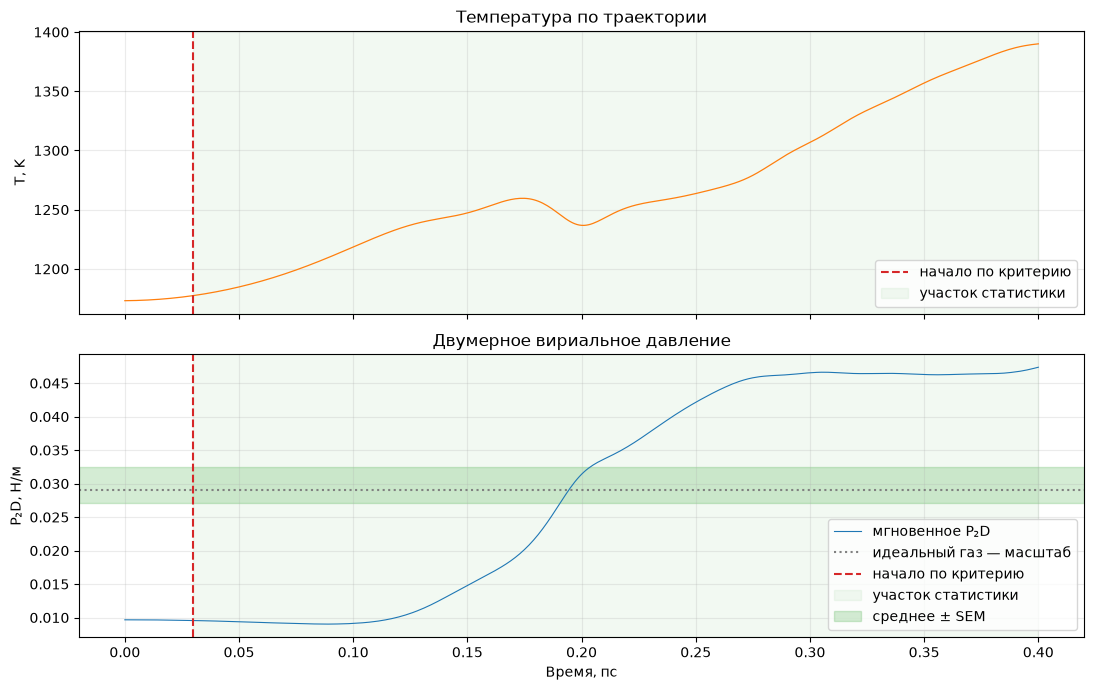

P̄ = 2.97845e-02 Н/м; стандартное отклонение s = 1.60244e-02 Н/м; SEM = 2.66518e-03 Н/м
Постпереходных наблюдений: 371; блоков для оценки SEM: 37


In [3]:
if criterion_met:
    stats = block_statistics(history['pressure_2d'], equilibrium_index, block_size=BLOCK_SIZE)
    pressure_mean = stats.mean
else:
    stats = None  # без обоснованного участка не рассчитываем P_eq
    pressure_mean = None

time_ps = history['time'] * 1e12
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(time_ps, history['temperature'], color='tab:orange', linewidth=0.9)
axes[0].set(title='Температура по траектории', ylabel='T, K')
axes[1].plot(time_ps, history['pressure_2d'], color='tab:blue', linewidth=0.8, label='мгновенное P₂D')
axes[1].axhline(ideal_pressure, color='gray', linestyle=':', label='идеальный газ — масштаб')
if criterion_met:
    start_time = time_ps[equilibrium_index]
    for axis in axes: axis.axvline(start_time, color='tab:red', linestyle='--', label='начало по критерию')
    for axis in axes: axis.axvspan(start_time, time_ps[-1], color='tab:green', alpha=0.06, label='участок статистики')
    axes[1].axhspan(stats.mean - stats.sem, stats.mean + stats.sem, color='tab:green', alpha=0.2, label='среднее ± SEM')
axes[1].set(title='Двумерное вириальное давление', xlabel='Время, пс', ylabel='P₂D, Н/м')
for axis in axes: axis.grid(alpha=0.25); axis.legend()
fig.tight_layout(); plt.show()

if criterion_met:
    print(f'P̄ = {stats.mean:.5e} Н/м; стандартное отклонение s = {stats.std:.5e} Н/м; SEM = {stats.sem:.5e} Н/м')
    print(f'Постпереходных наблюдений: {stats.n_samples}; блоков для оценки SEM: {stats.n_samples // BLOCK_SIZE}')
else:
    print('Среднее давление всей траектории:', f'{np.mean(history["pressure_2d"]):.5e} Н/м')
    print('Это только описательная средняя по конечной траектории, НЕ оценка равновесного давления.')


### Интерпретация и ограничения статистики

Признаком подхода к стационарному режиму служит отсутствие устойчивого тренда средних температуры и давления на последовательных окнах, а не отсутствие мгновенных колебаний. В этой реализации окна сравнивают средние и tolerances (2% для температуры и 5% масштаба идеального давления) на входе функции. Поскольку давление и температура могут быть автокоррелированы, соседние точки траектории не независимы. Блочная SEM уменьшает риск искусственно считать каждую точку независимой, но выбор размера блока тоже следует проверить: повторить анализ с более крупными блоками, проверить график и увеличить продолжительность расчёта.

Критерий может дать ложное срабатывание на коротком случайном плато или не сработать при стационарном ряду из-за строгих допусков. Поэтому научно корректная проверка включает несколько независимых seed, увеличение длины траектории, сравнение средних разных окон и устойчивость результата к размеру блока. Если критерий не выполнен, следует сообщить, сколько шагов рассчитано, показать весь ряд и продолжить расчёт; объявлять равновесие вручную нельзя.

## 5. Экспорт и вывод

`np.savetxt` сохраняет только фактически рассчитанные временные значения. Импортированные `Path` формирует переносимый путь, `mkdir(parents=True, exist_ok=True)` создаёт каталог, если его ещё нет. Сводка ниже строится программно и разделяет случай «критерий выполнен» от случая «не выполнен».

In [4]:
output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task2_equilibrium'
output_dir.mkdir(parents=True, exist_ok=True)
np.savetxt(output_dir / 'pressure_timeseries.csv', np.column_stack((history['step'], history['time'], history['temperature'], history['pressure_2d'])), delimiter=',', header='step,time_s,temperature_K,pressure_2d_N_per_m', comments='')
if criterion_met:
    start_step = int(history['step'][equilibrium_index])
    conclusion = f'Критерий выполнен на шаге {start_step}; давление {stats.mean:.5e} Н/м, s={stats.std:.3e} Н/м, SEM={stats.sem:.3e} Н/м по {stats.n_samples} наблюдениям. Это эвристическая оценка.'
else:
    mean_pressure = np.mean(history['pressure_2d'])
    conclusion = f'На {N_STEPS} шагах критерий не выполнен. Описательное среднее ряда {mean_pressure:.5e} Н/м; равновесное давление не заявляется.'
display(Markdown(f'**Вывод ({MODE}, seed {SEED}):** {conclusion}'))
print(f'Ряд давления сохранён: {output_dir.relative_to(PROJECT_ROOT) / "pressure_timeseries.csv"}')


**Вывод (DEMO, seed 7):** Критерий выполнен на шаге 30; давление 2.97845e-02 Н/м, s=1.602e-02 Н/м, SEM=2.665e-03 Н/м по 371 наблюдениям. Это эвристическая оценка.

Ряд давления сохранён: output/notebooks/task2_equilibrium/pressure_timeseries.csv


## Возможные вопросы преподавателя

1. **Что понимается под равновесием?** Макроскопические средние не имеют заметного временного тренда при неизменных условиях; микроскопические флуктуации остаются.
2. **Почему начальное состояние может быть неравновесным?** Решёточные координаты — удобная неперекрывающаяся инициализация, но не случайная выборка равновесного распределения.
3. **Что делает `find_equilibration_index`?** Сравнивает средние температуры и давления в последовательных блоках и возвращает первый индекс, удовлетворяющий заданному набору допусков.
4. **Почему это не строгое доказательство равновесия?** Любой конечный критерий ограничен выбранными окнами, допусками и конкретным шумным seed; он может ошибиться.
5. **Зачем блокировать временной ряд?** Блочные средние частично учитывают автокорреляцию и дают более реалистичную оценку неопределённости среднего.
6. **Чем стандартное отклонение отличается от SEM?** Отклонение характеризует разброс наблюдений; SEM — неопределённость оценки среднего.
7. **Почему последовательные кадры коррелированы?** Положение и скорость меняются непрерывно, поэтому состояние на соседних шагах близко.
8. **Что делать, если критерий не выполнен?** Не объявлять равновесие; показать всю траекторию, продлить расчёт, исследовать другие seed и проверить устойчивость к размеру блока.
9. **В каких единицах давление?** Н/м для 2D вириального pressure; Па получаются только после деления на условную толщину.
10. **Почему среднее полного ряда не обязательно $P_{eq}$?** В него может входить неравновесный переходный участок.